# Graphical abstract

Two rows: Freshwater Beach (FWB, low density) on top, Special Study Beach (SSB, high density) below.
Columns from left to right: overview map (Figure 1a), seal density in the breeding area (all seals detected per m²,
averaged over all images of the days monitored at both colonies), birds per pup as FWB : SSB rate ratio with 95% CI
(giant petrel, brown skua, snowy sheathbill; Figure 4) and the spatial overlap of each bird species with pups (Figure 5).

Seal densities (4×) and rate ratios are taken from the Results of the manuscript. The small input files in `assets/graphical_abstract/` are
written once by the *prepare* cell (needs `FWB.csv` and `SSB.csv`); afterwards the notebook runs in seconds.
The helper functions are copied unchanged from `analysis.ipynb`.

In [1]:
import json
from pathlib import Path
from xml.dom.minidom import parse

import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter, zoom

import cameratransform as ct
import clickpoints
import contourpy
from cameratransform import moveDistance
from pyproj import CRS, Transformer
from shapely.geometry import GeometryCollection, MultiPolygon, Polygon, box, mapping, shape
from shapely.ops import unary_union

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredOffsetbox, DrawingArea, HPacker, OffsetImage, TextArea, VPacker
from matplotlib.patches import Circle, FancyArrowPatch, Patch, Rectangle

FIG = Path("figures")
ICONS = Path("assets/icons/transparent")         # drawings without background (3seals.png from assets/icons)
DATA = Path("assets/graphical_abstract")                   # small inputs, written by the "prepare" cell
FS = 10                                                     # base font size

colors = {"fwb": "salmon", "ssb": "#5254A3", "male": "#FF7F0E", "female": "#1F77B4", "pup": "#2CA02C",
          "seal": "0.4", "overlap": "#D7191C", "giant petrel": "#9467bd", "skua": "#8C564B", "sheathbill": "#e377c2"}
MAP_COLORS = {"background": "#A0A0A0", "water": "#AAD3DF", "rocks": "#A0A0A0", "vegetation": "#CDEBB0",
              "beach": "#E6DCD2", "passway": "#F2EFE9", "stream": "#AAD3DF", "building": "#F2EFE9", "jetty": "#F2EFE9"}
FIG1_COLORS = dict(MAP_COLORS, vegetation="#b3bd6c")
SEALS = ["male", "female", "pup"]
BIRDS = ["giant petrel", "skua", "sheathbill"]
NAMES = {"giant petrel": "Giant petrels", "skua": "Brown skuas", "sheathbill": "Snowy sheathbills"}
BEACHES = {"FWB": "Freshwater Beach", "SSB": "Special Study Beach"}
IMG_H, IMG_W = 3456, 4608                                   # image size of both cameras (px)
SSB_SHIFT_M, SSB_SHIFT_DEG = 8, 45                          # SSB camera position correction (as Figure 1)
SITES = {"both": {"png": "map/both_areas.png", "kml": "map/both_areas.kml", "cdb": "map/both_areas_v1.cdb"},
         "SSB": {"png": "map/SSB.png", "kml": "map/SSB.kml", "cdb": "map/SSB_v1.cdb"},
         "FWB": {"png": "map/FWB.png", "kml": "map/FWB.kml", "cdb": "map/FWB_v1.cdb"}}
LAYERS = {"FWB": ["background", "rocks", "beach", "water", "vegetation", "passway", "stream", "building"],
          "SSB": ["background", "water", "rocks", "beach", "vegetation", "passway"]}

# Results (manuscript): seal density per m² (corrected Voronoi peaks) and bird-to-pup rate ratios (GLMM)
density = {"FWB": {"male": 0.02, "female": 0.12, "pup": 0.12, "all": 0.27},
           "SSB": {"male": 0.04, "female": 0.69, "pup": 0.50, "all": 1.13}}
rate_ratio = {"giant petrel": 3.8, "skua": 5.8, "sheathbill": 0.57}
rate_ratio_ci = {"giant petrel": (2.05, 7.10), "skua": (2.73, 12.45), "sheathbill": (0.37, 0.90)}   # 95% CI (results/rate_ratios.csv, pups, maxlags 3)

### Helper functions (from `analysis.ipynb`)

In [2]:
def rings_to_multipolygon(rings, close_tol=1e-9, fix_invalid=True):
    # Closed contour lines -> valid shapely MultiPolygon.
    polys = []
    for r in rings:
        r = np.asarray(r)
        if r.shape[0] < 4:
            continue
        if not np.allclose(r[0], r[-1], atol=close_tol, rtol=0):
            r = np.vstack([r, r[0]])
        p = Polygon(r)
        if p.is_empty or p.area <= 0:
            continue
        if fix_invalid and not p.is_valid:
            p = p.buffer(0)
        if not p.is_empty and p.area > 0:
            polys.append(p)
    if not polys:
        return MultiPolygon([])
    u = unary_union(polys)
    if isinstance(u, GeometryCollection):
        u = unary_union([g for g in u.geoms if g.geom_type in ("Polygon", "MultiPolygon")])
    if u.geom_type == "Polygon":
        return MultiPolygon([u])
    if u.geom_type == "MultiPolygon":
        return u
    return MultiPolygon([])


def kde_outline_from_hist2d(x, y, prob=0.99, resolution=1.0, sigma=1, padding=0.1):
    # Occupancy area containing `prob` of all detections: 2D histogram on a `resolution` (m) grid,
    # Gaussian smoothing (`sigma` cells), contour at the level that encloses `prob` of the smoothed mass.
    # Returns (H, Hs, lines, rings, MultiPolygon).
    x, y = np.asarray(x), np.asarray(y)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    if x.size == 0:
        return None, None, [], [], MultiPolygon([])

    xmin, xmax, ymin, ymax = x.min(), x.max(), y.min(), y.max()
    w, h = xmax - xmin, ymax - ymin
    xmin -= padding * w; xmax += padding * w
    ymin -= padding * h; ymax += padding * h
    n_bins_x = max(1, int(np.ceil((xmax - xmin) / resolution)))
    n_bins_y = max(1, int(np.ceil((ymax - ymin) / resolution)))
    H, xedges, yedges = np.histogram2d(x, y, bins=[n_bins_x, n_bins_y], range=[[xmin, xmax], [ymin, ymax]])
    Hs = gaussian_filter(H, sigma=sigma, mode="constant")

    vals = Hs.ravel()
    order = np.argsort(vals)[::-1]
    cum = np.cumsum(vals[order])
    k = np.searchsorted(cum, prob * vals.sum())
    k = min(max(int(k), 0), vals.size - 1)
    thresh = float(vals[order][k])
    vmax, eps = float(vals[order][0]), np.finfo(float).eps        # guard against degenerate levels
    if thresh <= 0:
        thresh = max(vmax * 1e-12, eps)
    if thresh >= vmax:
        thresh = vmax - max(vmax * 1e-12, eps)

    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    lines = contourpy.contour_generator(x=xc, y=yc, z=Hs.T, name="serial").lines(thresh)
    rings = [L for L in lines if len(L) >= 4 and np.allclose(L[0], L[-1])]
    return H, Hs, lines, rings, rings_to_multipolygon(rings)


def overlap_percent(a, b):
    # Percentage of area `a` covered by area `b`.
    if a is None or b is None or a.is_empty or b.is_empty:
        return 0.0
    return 100.0 * a.intersection(b).area / a.area


def polygon_points_df(cdb, poly_type, id_col="poly_id"):
    return pd.DataFrame([(pid, x, y) for pid, poly in enumerate(cdb.getPolygons(type=poly_type), 1)
                         for x, y in poly.points], columns=[id_col, "x", "y"])


def read_cdb_layers(cdb_path, wanted_layers):
    # Control points, field of view and map polygons (rocks, water, ...) drawn in ClickPoints.
    with clickpoints.DataFile(cdb_path) as cdb:
        marker = pd.DataFrame([[m.x, m.y, m.id] for m in cdb.getMarkers(type="marker")], columns=["x", "y", "id"])
        fov = pd.DataFrame([[m.x, m.y, m.x + m.width, m.y + m.height, m.id] for m in cdb.getRectangles(type="fov")],
                           columns=["x1", "y1", "x2", "y2", "id"])
        polys = {}
        for layer in wanted_layers:
            try:
                df = polygon_points_df(cdb, layer)
                if not df.empty:
                    polys[layer] = df
            except clickpoints.MarkerTypeDoesNotExist:
                continue
    return marker, fov, polys


def read_kml_corners(kml_path):
    doc = parse(kml_path)
    coords_txt = doc.getElementsByTagName("coordinates")[0].firstChild.nodeValue.strip()
    pts = [tuple(map(float, c.split(",")[:2])) for c in coords_txt.split()]
    return pd.DataFrame(pts, columns=["lon", "lat"])


def fit_pixel2lonlat(marker):
    # Affine map from map pixels to lon/lat, fitted to the control points.
    A = np.hstack([marker[["x", "y"]].to_numpy(), np.ones((len(marker), 1))])
    a, b, c = np.linalg.lstsq(A, marker["lon"].to_numpy(), rcond=None)[0]
    d, e, f = np.linalg.lstsq(A, marker["lat"].to_numpy(), rcond=None)[0]

    def pixel2lonlat(x, y):
        x, y = np.asarray(x), np.asarray(y)
        return a * x + b * y + c, d * x + e * y + f
    return pixel2lonlat


def plot_polygons(poly_df, color, ax, pixel2ll, zorder=2, alpha=1.0, edgecolor=None):
    for _, group in poly_df.groupby("poly_id"):
        lons, lats = pixel2ll(group["x"].values, group["y"].values)
        ax.add_geometries([Polygon(zip(lons, lats))], crs=ccrs.PlateCarree(),
                          facecolor=color, edgecolor=edgecolor, alpha=alpha, zorder=zorder)


def plot_site_map(ds, ax, elements, alpha=1.0, layer_colors=None):
    # Georeferenced aerial image of a site with the drawn map layers.
    img = plt.imread(ds["png"])
    marker, fov, polys = read_cdb_layers(ds["cdb"], wanted_layers=elements)
    marker[["lon", "lat"]] = read_kml_corners(ds["kml"])[["lon", "lat"]].to_numpy()
    pixel2ll = fit_pixel2lonlat(marker)

    h, w = img.shape[:2]
    lons, lats = pixel2ll(np.array([0, w, w, 0]), np.array([0, 0, h, h]))
    extent_image = [lons.min(), lons.max(), lats.min(), lats.max()]
    r = fov.iloc[0]
    lons, lats = pixel2ll(np.array([r.x1, r.x1, r.x2, r.x2]), np.array([r.y1, r.y2, r.y1, r.y2]))
    ax.set_extent([lons.min(), lons.max(), lats.min(), lats.max()], crs=ccrs.PlateCarree())
    ax.imshow(img, origin="upper", extent=extent_image, transform=ccrs.PlateCarree(), zorder=0)
    layer_colors = layer_colors or MAP_COLORS
    for layer in elements:
        if layer in polys:
            plot_polygons(polys[layer], layer_colors[layer], ax, pixel2ll, alpha=alpha)


def meters_per_deg_lon(lat_deg):
    phi = np.deg2rad(lat_deg)
    return 111412.84 * np.cos(phi) - 93.5 * np.cos(3 * phi) + 0.118 * np.cos(5 * phi)


def add_scalebar(ax, length_m, label=None, pad_frac=0.04, linewidth=3, color="k"):
    # Horizontal scale bar in the lower left corner of a cartopy axis.
    lonmin, lonmax, latmin, latmax = ax.get_extent(ccrs.PlateCarree())
    x0 = lonmin + pad_frac * (lonmax - lonmin)
    y0 = latmin + pad_frac * (latmax - latmin)
    x1 = x0 + length_m / meters_per_deg_lon(y0)
    ax.plot([x0, x1], [y0, y0], transform=ccrs.PlateCarree(), color=color, linewidth=linewidth,
            solid_capstyle="butt", zorder=100)
    ax.text((x0 + x1) / 2, y0 + 0.02 * (latmax - latmin), label or f"{int(length_m)} m",
            transform=ccrs.PlateCarree(), ha="center", va="bottom", fontsize=9, color=color, zorder=100)


def ring_xy_to_latlon(cam, ring_coords, z_plane=0.0):
    pts = np.asarray(ring_coords, dtype=float)
    if pts.ndim != 2 or pts.shape[0] < 4:
        return None
    gps = np.asarray(cam.gpsFromSpace(np.column_stack([pts, np.full(len(pts), z_plane)])), dtype=float)
    return gps[:, [1, 0]]                                              # (lat, lon) -> (lon, lat) order swap


def multipolygon_to_gps(cam, geom_xy, z_plane=0.0):
    # Polygon/MultiPolygon in camera space (m) -> MultiPolygon in lon/lat for cartopy.
    if geom_xy is None or geom_xy.is_empty:
        return MultiPolygon([])
    polys = [geom_xy] if geom_xy.geom_type == "Polygon" else [g for g in geom_xy.geoms if g.geom_type == "Polygon"]
    out = []
    for p in polys:
        ext = ring_xy_to_latlon(cam, p.exterior.coords, z_plane)
        if ext is None:
            continue
        holes = [h for h in (ring_xy_to_latlon(cam, r.coords, z_plane) for r in p.interiors) if h is not None]
        q = Polygon(ext, holes=holes)
        q = q if q.is_valid else q.buffer(0)
        if not q.is_empty and q.area > 0:
            out.append(q)
    if not out:
        return MultiPolygon([])
    u = unary_union(out)
    return MultiPolygon([u]) if u.geom_type == "Polygon" else u


def load_calibrations(folder, shift=None):
    # All camera calibrations of one camera; file names end with _<start>_<end>.ct
    cams = []
    for p in sorted(Path(folder).glob("*.ct")):
        cam = ct.load_camera(str(p))
        if shift is not None:
            lat, lon = moveDistance([cam.gps_lat, cam.gps_lon], *shift)
            cam.setGPSpos(lat, lon, cam.elevation_m)
        start, end = (pd.to_datetime(s, format="%Y%m%d-%H%M%S") for s in p.stem.split("_")[1:3])
        cams.append(dict(name=p.name, cam=cam, start=start, end=end))
    return cams


def fov_wedge(cam, y_pref, far_km):
    # Triangle camera -> far left / far right, through the ground points of the image edges on one image row.
    def edges(y):
        px = np.array([[0, y], [IMG_W - 1, y]], dtype=float)
        px[:, 1] = (IMG_H - 1) - px[:, 1]                                  # top-origin -> camera convention
        g = np.asarray(cam.gpsFromImage(px))
        return g if np.isfinite(g[:, :2]).all() else None

    g = edges(y_pref)
    for dy in range(5, 401, 5):                                             # nearest row with both edges on the ground
        if g is not None:
            break
        for y in (y_pref - dy, y_pref + dy):
            if 0 <= y < IMG_H and (g := edges(y)) is not None:
                break
    if g is None:
        return None
    lon0, lat0 = float(cam.gps_lon), float(cam.gps_lat)
    loc = CRS.from_proj4(f"+proj=aeqd +lat_0={lat0} +lon_0={lon0} +datum=WGS84 +units=m +no_defs")
    to_loc = Transformer.from_crs(CRS.from_epsg(4326), loc, always_xy=True)
    to_geo = Transformer.from_crs(loc, CRS.from_epsg(4326), always_xy=True)
    c = np.array(to_loc.transform(lon0, lat0))
    far = []
    for lat, lon in g[:, :2]:
        v = np.array(to_loc.transform(lon, lat)) - c
        far.append(to_geo.transform(*(c + v / np.linalg.norm(v) * far_km * 1000)))
    return Polygon([far[0], far[1], (lon0, lat0)])


def draw_zoom_link(fig, ax_main, ax_zoom, color="k", lw=1):
    # Rectangle of the zoom extent on the overview map, connected to the left edge of the zoom panel.
    lonmin, lonmax, latmin, latmax = ax_zoom.get_extent(crs=ccrs.PlateCarree())
    ax_main.add_patch(Rectangle((lonmin, latmin), lonmax - lonmin, latmax - latmin, transform=ccrs.PlateCarree(),
                                fill=False, edgecolor=color, linewidth=lw, zorder=30))
    to_fig = ccrs.PlateCarree()._as_mpl_transform(ax_main) + fig.transFigure.inverted()
    tr, br = to_fig.transform((lonmax, latmax)), to_fig.transform((lonmax, latmin))
    bb = ax_zoom.get_position()
    for (x0, y0), (x1, y1) in [(tr, (bb.x0, bb.y1)), (br, (bb.x0, bb.y0))]:
        fig.lines.append(Line2D([x0, x1], [y0, y1], transform=fig.transFigure, color=color, lw=lw, zorder=50))


def daily_max_abundance(df):
    # Daily abundance per class = maximum number of detections in any image of that day.
    counts = df.groupby([pd.to_datetime(df["timestamp"]).dt.normalize().rename("date"), "filename", "class"]).size()
    return counts.groupby(level=["date", "class"]).max().unstack(fill_value=0)


def compared_days(daily_fwb, daily_ssb, ref="pup"):
    # Days after the first-born pup at each colony with at least one `ref` animal at both colonies.
    f = daily_fwb[(daily_fwb.index > FIRST_PUP["FWB"]) & (daily_fwb[ref] > 0)].index
    s = daily_ssb[(daily_ssb.index > FIRST_PUP["SSB"]) & (daily_ssb[ref] > 0)].index
    return f.intersection(s).sort_values()

## Data

In [3]:
# One-off: small input files for the graphical abstract (needs FWB.csv / SSB.csv; slow, only runs if files are missing)
CSV_DIR = Path(".")                                         # folder with FWB.csv / SSB.csv (Zenodo)
cam = {"FWB": ct.load_camera("map/fwb_cam.ct"), "SSB": ct.load_camera("map/ssb_cam.ct")}
DATA.mkdir(parents=True, exist_ok=True)
if not (DATA / "fov.json").exists():
    # fields of view: union of all calibrations (Figure 1a) and its left / right edge as seen from the camera
    cams = {"FWB": load_calibrations("map/cameras/fwb"),
            "SSB": load_calibrations("map/cameras/ssb", shift=(SSB_SHIFT_M, SSB_SHIFT_DEG))}
    fov = {}
    for b in cams:
        union = unary_union([w for c in cams[b] if (w := fov_wedge(c["cam"], int(IMG_H * 0.4), far_km=0.5)) is not None]).buffer(0)
        lon0, lat0 = float(cams[b][0]["cam"].gps_lon), float(cams[b][0]["cam"].gps_lat)
        pts = np.array(union.exterior.coords)
        dx = (pts[:, 0] - lon0) * meters_per_deg_lon(lat0)
        dy = (pts[:, 1] - lat0) * 111_320
        far = np.hypot(dx, dy) > 20                                          # ignore points at the camera
        ang = np.arctan2(dy[far], dx[far])
        ang = np.unwrap(ang - np.median(ang)) + np.median(ang)
        edges = [pts[far][np.argmin(ang)].tolist(), pts[far][np.argmax(ang)].tolist()]
        fov[b] = {"camera": [lon0, lat0], "edges": edges, "union": mapping(union)}
    json.dump(fov, open(DATA / "fov.json", "w"), indent=1)
    print("written:", *sorted(p.name for p in DATA.iterdir()))

# 99% occupancy areas of pups and birds (Figure 5) and season-integrated birds per pup (Figure 4)
if not (DATA / "areas.json").exists() or not (DATA / "numbers.json").exists():
    areas, numbers, abundance = {}, {"per_pup": {}, "overlap": {}}, {}
    for b in ["FWB", "SSB"]:
        df = pd.read_csv(CSV_DIR / f"{b}.csv", usecols=["filename", "timestamp", "class", "x_m", "y_m"])
        df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y-%m-%d %H:%M:%S")
        abundance[b] = daily_max_abundance(df)
        xy = df[["class", "x_m", "y_m"]].dropna()
        poly = {c: kde_outline_from_hist2d(*xy.loc[xy["class"] == c, ["x_m", "y_m"]].values.T)[4] for c in ["pup"] + BIRDS}
        for s in BIRDS:
            numbers["overlap"][f"{b}|{s}"] = overlap_percent(poly["pup"], poly[s])
        areas[b] = {c: mapping(multipolygon_to_gps(cam[b], p)) for c, p in poly.items()}
    days = compared_days(abundance["FWB"], abundance["SSB"], "pup")
    for b in ["FWB", "SSB"]:
        for s in BIRDS:
            numbers["per_pup"][f"{b}|{s}"] = abundance[b].loc[days, s].sum() / abundance[b].loc[days, "pup"].sum()
    json.dump(areas, open(DATA / "areas.json", "w"))
    json.dump(numbers, open(DATA / "numbers.json", "w"), indent=1)
    print("written: areas.json, numbers.json")

# days with images per beach
if not (DATA / "days.json").exists():
    days = {}
    for b in ["FWB", "SSB"]:
        t = pd.read_csv(CSV_DIR / f"{b}.csv", usecols=["timestamp"])["timestamp"]
        days[b] = sorted(t.str[:10].unique().tolist())
    json.dump(days, open(DATA / "days.json", "w"))
    print("written: days.json")


# season-mean seal density: seals per m² per image on a 1 m grid (camera space), days monitored at both beaches
if not (DATA / "density.npz").exists():
    common = sorted(set.intersection(*(set(v) for v in json.load(open(DATA / "days.json")).values())))
    out = {}
    for b in ["FWB", "SSB"]:
        df = pd.read_csv(CSV_DIR / f"{b}.csv", usecols=["filename", "timestamp", "class", "x_m", "y_m"])
        df = df[df["timestamp"].str[:10].isin(common)]
        n_img = df["filename"].nunique()
        s = df[df["class"].isin(SEALS)].dropna(subset=["x_m", "y_m"])
        xe = np.arange(np.floor(s["x_m"].min()) - 3, np.ceil(s["x_m"].max()) + 4)
        ye = np.arange(np.floor(s["y_m"].min()) - 3, np.ceil(s["y_m"].max()) + 4)
        hist = np.histogram2d(s["x_m"], s["y_m"], bins=[xe, ye])[0]
        X, Y = np.meshgrid(xe, ye, indexing="ij")              # cell corners
        gps = np.asarray(cam[b].gpsFromSpace(np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])))
        out[f"{b}_density"] = gaussian_filter(hist / n_img, sigma=1.5).astype(np.float32)   # cells of 1 m²
        out[f"{b}_lat"], out[f"{b}_lon"] = gps[:, 0].reshape(X.shape), gps[:, 1].reshape(X.shape)
        print(f"{b}: {n_img} images on {len(common)} days")
    np.savez_compressed(DATA / "density.npz", **out)
    print("written: density.npz")

In [4]:
fov = {b: dict(v, union=shape(v["union"])) for b, v in json.load(open(DATA / "fov.json")).items()}
areas = {b: {c: shape(g) for c, g in v.items()} for b, v in json.load(open(DATA / "areas.json")).items()}
numbers = json.load(open(DATA / "numbers.json"))
_d = np.load(DATA / "density.npz")
seal_density = {b: {k: _d[f"{b}_{k}"] for k in ["density", "lon", "lat"]} for b in BEACHES}   # seals per m² per image
EXTENTS = json.load(open(DATA / "extents.json")) if (DATA / "extents.json").exists() else {}   # map areas chosen with graphical_abstract_select.py
per_pup = {tuple(k.split("|")): v for k, v in numbers["per_pup"].items()}      # birds per pup (season-integrated)
overlap = {tuple(k.split("|")): v for k, v in numbers["overlap"].items()}      # % of the pup area covered by the bird area
for (b, s), v in per_pup.items():
    print(f"{b} {s}: {100 * v:.1f} per 100 pups, overlap {overlap[b, s]:.0f}%")

FWB giant petrel: 9.1 per 100 pups, overlap 87%
FWB skua: 16.8 per 100 pups, overlap 79%
FWB sheathbill: 10.8 per 100 pups, overlap 94%
SSB giant petrel: 2.3 per 100 pups, overlap 25%
SSB skua: 2.7 per 100 pups, overlap 53%
SSB sheathbill: 18.8 per 100 pups, overlap 99%


## Layout

In [5]:
def make_layout():
    """Panel grid: map spanning both rows | density map | bird-to-pup ratio spanning both rows | 3 x overlap.
    The middle grid row is the gap between FWB (top) and SSB (bottom)."""
    fig = plt.figure(figsize=(12, 6.6))
    #            map  _     dens  _     ratio _     ov1  ov2  ov3
    widths = [1.6, 0.12, 1.75, 0.42, 1.2, 0.35, 1.0, 1.0, 1.0]
    gs = fig.add_gridspec(3, len(widths), width_ratios=widths, height_ratios=[1, 0.45, 1],
                          left=0.02, right=0.98, top=0.86, bottom=0.2, wspace=0.08, hspace=0)
    ax = {"map": fig.add_subplot(gs[:, 0], projection=ccrs.Mercator()), "ratio": fig.add_subplot(gs[:, 4])}
    for r, b in [(0, "FWB"), (2, "SSB")]:
        ax[b, "density"] = fig.add_subplot(gs[r, 2], projection=ccrs.Mercator())
        for k, s in enumerate(BIRDS):
            ax[b, "overlap", s] = fig.add_subplot(gs[r, 6 + k], projection=ccrs.Mercator())
    for key, a in ax.items():
        a.set_xticks([]); a.set_yticks([])
        if isinstance(key, tuple):
            for sp in a.spines.values():
                sp.set_edgecolor(colors[key[0].lower()]); sp.set_linewidth(1.5)
    return fig, ax


def placeholder(a, text):
    a.text(0.5, 0.5, text, transform=a.transAxes, ha="center", va="center", fontsize=FS - 2, color="0.6", wrap=True)


def between_rows(fig, ax, col_key, fwb, ssb, ratio=None):
    """Values in the gap between the FWB and SSB panel of one column: FWB value under the FWB panel, SSB value over
    the SSB panel, and the comparison in the middle."""
    top, bot = ax[("FWB",) + col_key].get_position(original=True), ax[("SSB",) + col_key].get_position(original=True)
    x = (top.x0 + top.x1) / 2
    kw = dict(ha="center", fontsize=FS + 2, fontweight="bold")
    fig.text(x, top.y0 - 0.012, fwb, va="top", color=colors["fwb"], **kw)
    fig.text(x, bot.y1 + 0.012, ssb, va="bottom", color=colors["ssb"], **kw)
    if ratio:
        fig.text(x, (top.y0 + bot.y1) / 2, ratio, ha="center", va="center", fontsize=FS, color="k")


def icon_below(fig, a, imgs, h=0.05, gap=0.012, widen=1.0):
    """Row of icons centred under a panel (h: height in figure fraction)."""
    p = a.get_position(original=True)
    w = p.width * widen
    ai = fig.add_axes([p.x0 + p.width / 2 - w / 2, p.y0 - gap - h, w, h])
    ai.set_axis_off()
    x = 0
    for img in imgs:
        iw = img.shape[1] / img.shape[0]
        ai.imshow(img, extent=[x, x + iw, 0, 1])
        x += iw + 0.1
    ai.set_xlim(-0.05, x - 0.05); ai.set_ylim(0, 1); ai.set_aspect("equal", adjustable="datalim")
    return ai


def panel_ratio(a):
    """Height / width of a panel in inches."""
    bb, (fw, fh) = a.get_position(original=True), a.figure.get_size_inches()
    return (bb.height * fh) / (bb.width * fw)


def zoom_box(a, lon, lat, pad=0.1):
    """Centre (lon, lat) and width (m) of the smallest panel-shaped extent around the points, with padding."""
    lat0 = np.mean(lat)
    mx, my = meters_per_deg_lon(lat0), 111_320.0
    w = (np.max(lon) - np.min(lon)) * mx * (1 + 2 * pad)
    h = (np.max(lat) - np.min(lat)) * my * (1 + 2 * pad)
    return (np.min(lon) + np.max(lon)) / 2, (np.min(lat) + np.max(lat)) / 2, max(w, h / panel_ratio(a))


def set_zoom(a, lon_c, lat_c, width_m):
    """Panel-shaped map extent of the given width (m) around a centre, shifted to stay inside the current map extent."""
    mx, my = meters_per_deg_lon(lat_c), 111_320.0
    height_m = width_m * panel_ratio(a)
    x0, x1, y0, y1 = a.get_extent(crs=ccrs.PlateCarree())
    hw, hh = width_m / 2 / mx, height_m / 2 / my
    lon_c = min(max(lon_c, x0 + hw), x1 - hw) if x1 - x0 > 2 * hw else (x0 + x1) / 2
    lat_c = min(max(lat_c, y0 + hh), y1 - hh) if y1 - y0 > 2 * hh else (y0 + y1) / 2
    a.set_extent([lon_c - width_m / 2 / mx, lon_c + width_m / 2 / mx,
                  lat_c - height_m / 2 / my, lat_c + height_m / 2 / my], crs=ccrs.PlateCarree())


DOT_D = 6                                                   # diameter (points) of every legend dot


def key(fig, xy, items, title=None, img=None, img_h=22, loc="upper center"):
    """Legend at figure position xy: optional drawing, then (colour, text) items in one row, optional title above."""
    fs = FS - 1
    row = []
    for color, text in items:
        dot = DrawingArea(DOT_D, DOT_D)
        dot.add_artist(Circle((DOT_D / 2, DOT_D / 2), DOT_D / 2, color=color))
        row.append(HPacker(children=[dot] + ([TextArea(text, textprops=dict(fontsize=fs))] if text else []),
                           align="center", pad=0, sep=3))
    head = [OffsetImage(img, zoom=img_h / img.shape[0])] if img is not None else []
    child = HPacker(children=head + row, align="center", pad=0, sep=8)
    if title:
        child = VPacker(children=[TextArea(title, textprops=dict(fontsize=fs)), child], align="center", pad=0, sep=4)
    box = AnchoredOffsetbox(loc=loc, child=child, frameon=False, bbox_to_anchor=xy,
                            bbox_transform=fig.transFigure, borderpad=0)
    fig.add_artist(box)
    return box


def gradient_bar(fig, axs, h=0.022, gap=0.008):
    """Predator -> scavenger bar right below a group of bird panels (axs: left to right), subtle grey gradient."""
    p0, p1 = axs[0].get_position(original=True), axs[-1].get_position(original=True)
    ab = fig.add_axes([p0.x0, p0.y0 - gap - h, p1.x1 - p0.x0, h])
    cmap = LinearSegmentedColormap.from_list("gradient", ["#A6A6A6", "#F0F0F0"])
    ab.imshow(np.linspace(0, 1, 256)[None, :], cmap=cmap, aspect="auto", extent=[0, 1, 0, 1])
    ab.text(0.02, 0.5, "predator", ha="left", va="center", fontsize=FS - 2, color="0.15")
    ab.text(0.98, 0.5, "scavenger", ha="right", va="center", fontsize=FS - 2, color="0.15")
    ab.set_axis_off()
    return ab

## Figure

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


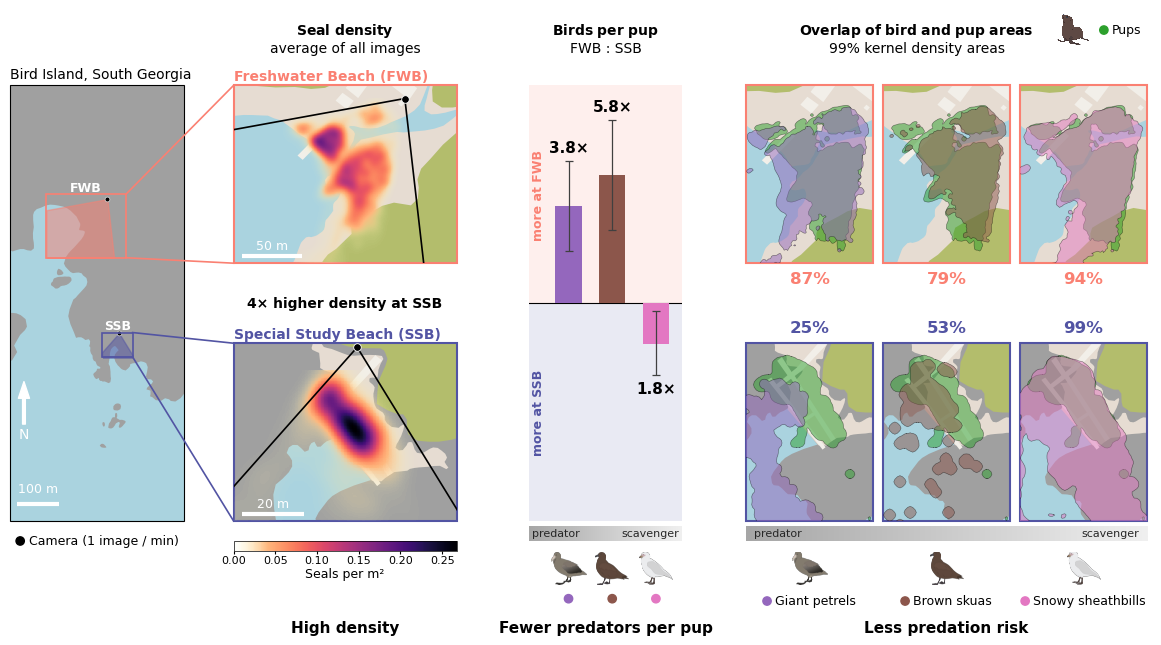

In [6]:
fig, ax = make_layout()
pc = ccrs.PlateCarree()

# headers
def header(keys, text, dy=0.045):
    p0, p1 = ax[keys[0]].get_position(original=True), ax[keys[-1]].get_position(original=True)
    return fig.text((p0.x0 + p1.x1) / 2, p0.y1 + dy, text, ha="center", va="bottom", fontsize=FS)
header([("FWB", "density")], "$\\bf{Seal\\ density}$\naverage of all images")
header(["ratio"], "$\\bf{Birds\\ per\\ pup}$\nFWB : SSB")
h_overlap = header([("FWB", "overlap", s) for s in BIRDS], "$\\bf{Overlap\\ of\\ bird\\ and\\ pup\\ areas}$\n99% kernel density areas")
for axs in [[ax["ratio"]], [ax["SSB", "overlap", s] for s in BIRDS]]:
    gradient_bar(fig, axs)
DROP = 0.035                                                # everything under the panels moves down by the bar

# --- (1) overview map, as Figure 1a ---
am = ax["map"]
plot_site_map(SITES["both"], am, ["background", "water", "rocks"], layer_colors=FIG1_COLORS)
add_scalebar(am, 100, color="white")
am.annotate("N", xy=(0.08, 0.32), xycoords="axes fraction", xytext=(0.08, 0.20), textcoords="axes fraction",
            ha="center", va="center", fontsize=FS, color="white",
            arrowprops=dict(facecolor="white", edgecolor="white", width=2, headwidth=8))
am.text(0.0, 1.01, "Bird Island, South Georgia", transform=am.transAxes, ha="left", va="bottom", fontsize=FS)

# --- (2) season-mean seal density, zoomed to the breeding area; same colour scale on both beaches ---
SMOOTH_M = 3                                                # extra smoothing of the 1 m density grid (m)
smooth = {b: gaussian_filter(seal_density[b]["density"], SMOOTH_M) for b in BEACHES}
VMAX = max(float(smooth[b].max()) for b in BEACHES)
_c = plt.get_cmap("magma_r")(np.linspace(0, 1, 256))
_c[:, 3] = np.clip(np.linspace(0, 1, 256) / 0.15, 0, 1)    # low densities fade out into the map
DENS_CMAP = ListedColormap(_c)
for b in BEACHES:
    a, col, sd = ax[b, "density"], colors[b.lower()], seal_density[b]
    plot_site_map(SITES[b], a, LAYERS[b], layer_colors=FIG1_COLORS)
    sel = EXTENTS.get("density", {}).get(b)                # chosen with graphical_abstract_select.py
    if sel:
        set_zoom(a, *sel["center"], sel["width_m"])
    else:                                                   # cells above 20% of the beach maximum
        D = sd["density"]
        i, j = np.nonzero(D > 0.2 * D.max())
        set_zoom(a, *zoom_box(a, sd["lon"][i, j], sd["lat"][i, j], pad=0.15))
    centre = lambda v: (v[:-1, :-1] + v[1:, 1:] + v[:-1, 1:] + v[1:, :-1]) / 4      # cell centres
    fine = lambda v: zoom(v, 4, order=1)                                              # 25 cm cells: no visible pixels
    a.pcolormesh(fine(centre(sd["lon"])), fine(centre(sd["lat"])), fine(smooth[b]), cmap=DENS_CMAP,
                 vmin=0, vmax=VMAX, shading="nearest", transform=pc, zorder=5, rasterized=True)
    lon0, lat0 = fov[b]["camera"]                           # field of view: left and right edge from the camera
    for lon1, lat1 in fov[b]["edges"]:
        a.plot([lon0, lon1], [lat0, lat1], transform=pc, color="k", lw=1.2, zorder=8)
    a.scatter(lon0, lat0, s=30, color="k", edgecolor="white", linewidth=0.6, transform=pc, zorder=12)
    x0, x1, y0, y1 = a.get_extent(crs=pc)
    width_m = (x1 - x0) * meters_per_deg_lon((y0 + y1) / 2)
    add_scalebar(a, 10 if width_m < 70 else 20 if width_m < 150 else 50, color="white")
    # where this is on the overview map
    am.add_geometries([fov[b]["union"].intersection(box(x0, y0, x1, y1))], crs=pc,
                      edgecolor=col, facecolor=col, alpha=0.5, zorder=6)
    fig.canvas.draw()
    draw_zoom_link(fig, am, a, color=col, lw=1.2)
    a.text(0.0, 1.01, f"{BEACHES[b]} ({b})", transform=a.transAxes, ha="left", va="bottom", fontsize=FS,
           fontweight="bold", color=col)
    am.text((x0 + x1) / 2, y1, b, transform=pc, ha="center", va="bottom", fontsize=FS - 1,
            color="white", fontweight="bold", zorder=31)
for lon, lat in [fov[b]["camera"] for b in BEACHES]:
    am.scatter(lon, lat, c="black", s=12, edgecolor="white", linewidth=0.4, transform=pc, zorder=10)
pm = am.get_position()
key(fig, (pm.x0 + pm.width / 2, pm.y0 - 0.012), [("k", "Camera (1 image / min)")])
# colour bar under the SSB map, ratio between the rows
pd_ = ax["SSB", "density"].get_position(original=True)
cax = fig.add_axes([pd_.x0, pd_.y0 - 0.045, pd_.width, 0.014])
cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(0, VMAX), DENS_CMAP), cax=cax, orientation="horizontal")
cb.set_label("Seals per m²", fontsize=FS - 1, labelpad=2)
cb.ax.tick_params(labelsize=FS - 2, length=2, pad=1)
cb.outline.set_linewidth(0.5)
pf = ax["FWB", "density"].get_position(original=True)
fig.text(pf.x0 + pf.width / 2, (pf.y0 + pd_.y1) / 2,
         f"{density['SSB']['all'] / density['FWB']['all']:.0f}× higher density at SSB",
         ha="center", va="center", fontsize=FS, fontweight="bold")

# --- (3) birds per pup: rate ratio FWB : SSB (log scale); up = more at FWB, down = more at SSB ---
ar = ax["ratio"]
LIM = np.log(20)
ar.axhspan(0, LIM, color=colors["fwb"], alpha=0.12, lw=0)
ar.axhspan(-LIM, 0, color=colors["ssb"], alpha=0.12, lw=0)
ar.axhline(0, color="k", lw=0.8)
for i, s in enumerate(BIRDS):
    rr, (lo, hi) = rate_ratio[s], rate_ratio_ci[s]
    ar.bar(i, np.log(rr), width=0.6, color=colors[s], zorder=3)
    ar.errorbar(i, np.log(rr), yerr=[[np.log(rr) - np.log(lo)], [np.log(hi) - np.log(rr)]], fmt="none",
                ecolor="0.25", elinewidth=0.9, capsize=3, capthick=0.9, zorder=4)
    up = rr >= 1
    ar.text(i, np.log(hi) + 0.08 if up else np.log(lo) - 0.08, f"{rr if up else 1 / rr:.1f}×", ha="center",
            va="bottom" if up else "top", fontsize=FS + 1, fontweight="bold", zorder=4)
for y, b in [(0.75, "FWB"), (0.25, "SSB")]:                # along the left edge, centred in each half
    ar.text(-0.68, (y - 0.5) * 2 * LIM, f"more at {b}", ha="center", va="center", rotation=90,
            fontsize=FS - 1, color=colors[b.lower()], fontweight="bold")
ar.set_xlim(-0.9, len(BIRDS) - 0.4); ar.set_ylim(-LIM, LIM)
for sp in ar.spines.values():
    sp.set_visible(False)

icon = {k: plt.imread(ICONS / f"{k.replace(' ', '_')}.png") for k in BIRDS}
icon["pup"] = plt.imread(ICONS / "pup.png")
pr = ar.get_position(original=True)
xlo, xhi = ar.get_xlim()
for i, s in enumerate(BIRDS):                              # icon + dot under each bar
    xc = pr.x0 + pr.width * (i - xlo) / (xhi - xlo)
    w = pr.width / len(BIRDS) * 0.95
    ai = fig.add_axes([xc - w / 2, pr.y0 - 0.012 - DROP - 0.05, w, 0.05])
    ai.imshow(icon[s]); ai.set_axis_off(); ai.set_aspect("equal", adjustable="datalim")
    key(fig, (xc, pr.y0 - 0.068 - DROP), [(colors[s], "")])

# --- (4) overlap of pup and bird 99% areas (as Figure 5), area chosen with graphical_abstract_select.py ---
for b in BEACHES:
    for s in BIRDS:
        a = ax[b, "overlap", s]
        plot_site_map(SITES[b], a, LAYERS[b], layer_colors=FIG1_COLORS)
        sel = EXTENTS.get("overlap", {}).get(b)
        if sel:
            set_zoom(a, *sel["center"], sel["width_m"])
        for c in ["pup", s]:
            a.add_geometries([areas[b][c]], crs=pc, facecolor=colors[c], edgecolor="k", lw=0.4, alpha=0.5, zorder=5)
for s in BIRDS:
    between_rows(fig, ax, ("overlap", s), *(f"{overlap[b, s]:.0f}%" for b in BEACHES))
    icon_below(fig, ax["SSB", "overlap", s], [icon[s]], h=0.05, gap=0.012 + DROP, widen=1.0)
    p = ax["SSB", "overlap", s].get_position(original=True)
    key(fig, (p.x0 + p.width / 2, p.y0 - 0.068 - DROP), [(colors[s], NAMES[s])])
# pups: right of the overlap title (key at the right edge of the panels, title moved left of it)
fig.canvas.draw()
inv = fig.transFigure.inverted()
hb = h_overlap.get_window_extent().transformed(inv)
pr3 = ax["FWB", "overlap", BIRDS[-1]].get_position(original=True)
kb = key(fig, (pr3.x1, hb.y1 - hb.height / 4), [(colors["pup"], "Pups")], img=icon["pup"], loc="center right")
fig.canvas.draw()
k0 = kb.get_window_extent().transformed(inv).x0
h_overlap.set_x(min(h_overlap.get_position()[0], k0 - 0.015 - hb.width / 2))

# --- messages ---
y_msg = pr.y0 - 0.115 - DROP
p0, p1 = ax["SSB", "overlap", BIRDS[0]].get_position(original=True), ax["SSB", "overlap", BIRDS[-1]].get_position(original=True)
for x, text in [(pd_.x0 + pd_.width / 2, "High density"), (pr.x0 + pr.width / 2, "Fewer predators per pup"),
                ((p0.x0 + p1.x1) / 2, "Less predation risk")]:
    fig.text(x, y_msg, text, ha="center", va="top", fontsize=FS + 1, fontweight="bold")

fig.savefig(FIG / "graphical_abstract.png", dpi=200, facecolor="white")
plt.show()